# 05 — Clasificación de siete clases y ajuste fino

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MiltonCuervo/ham10000-skin-lesion-classification/blob/main/05_clasificacion_multiclase.ipynb)

Ejecución local: abre Jupyter desde la carpeta del proyecto y selecciona **Python (HAM10000 local GPU)**. Ejecuta en orden 01–05. Los resultados se guardan localmente; no se monta Drive. En Colab, usa `/content` como carpeta del proyecto y ejecuta primero 01 y 02.


## Resultados finales de test verificados

Modelo: **ResNet50 multiclase con ajuste fino**. Selección realizada previamente mediante validación (balanced accuracy: 0.7281). Evaluación sobre **1.494 imágenes de test**, con lesiones separadas de entrenamiento y validación.

| Métrica de test | Resultado |
|---|---:|
| Balanced accuracy | 0.7123 |
| F1 macro | 0.5814 |
| AUC-ROC OvR macro | 0.9429 |
| Accuracy | 0.7309 |

Métricas contrastadas con las predicciones guardadas y el checkpoint seleccionado. Las curvas de aprendizaje, la matriz de confusión y la ROC permanecen en las salidas del notebook. La revisión no reentrenó ni modificó la selección usando test.

| Clase | Imágenes en test | Precisión | Sensibilidad | F1 |
|---|---:|---:|---:|---:|
| akiec | 63 | 0.5500 | 0.6984 | 0.6154 |
| bcc | 68 | 0.5811 | 0.6324 | 0.6056 |
| bkl | 152 | 0.4459 | 0.6513 | 0.5294 |
| df | 7 | 0.1250 | 0.7143 | 0.2128 |
| mel | 187 | 0.4792 | 0.6150 | 0.5386 |
| nv | 996 | 0.9516 | 0.7701 | 0.8513 |
| vasc | 21 | 0.5938 | 0.9048 | 0.7170 |

Para melanoma, se clasificaron correctamente **115 de 187** imágenes: sensibilidad **61,50 %** y **72 errores de clasificación**. La clase `df` cuenta con solo **7** imágenes de test y precisión **12,50 %**, por lo que su resultado debe interpretarse con cautela. La AUC macro alta no elimina estas limitaciones de sensibilidad y precisión.


## 1. Configuración local

In [1]:
from pathlib import Path
import os, json, hashlib, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
PROJECT = Path.cwd().resolve()  # Abrir Jupyter desde la carpeta del proyecto.
DATA = PROJECT/'data'/'ham10000'
SPLITS = PROJECT/'data'/'splits'
CACHE = PROJECT/'data'/'processed_224'
SEED = 42
CLASSES = ['akiec','bcc','bkl','df','mel','nv','vasc']
POSITIVE = {'mel','bcc','akiec'}

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, roc_curve
MODE = 'full'  # 'smoke': muestra mínima para comprobar el código, sin test final.
RUN_ID = 'local_v2'  # Cambiar si modificas arquitectura, resolución o hiperparámetros.
BATCH_SIZE = 8
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda' and torch.cuda.get_device_capability(0)[0] >= 7
# La GTX 1050 usa FP32: no tiene Tensor Cores.
torch.set_num_threads(2)
assert MODE in {'full','smoke'}
RUNS = PROJECT/'results'/MODE/RUN_ID
RUNS.mkdir(parents=True, exist_ok=True)
print('PyTorch:',torch.__version__, '| Dispositivo:',DEVICE,
      '| GPU:',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'ninguna', '| AMP:',AMP)

PyTorch: 2.6.0+cu118 | Dispositivo: cuda | GPU: NVIDIA GeForce GTX 1050 | AMP: False


## 2. Datos multiclase

In [2]:
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEVICE.type == 'cuda': torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def load_partitions(multiclass=False):
    info = json.loads((SPLITS/'manifest_local.json').read_text())
    raw = {n:pd.read_csv(SPLITS/f'{n}.csv')[['image_id','lesion_id','dx']] for n in ['train','valid','test']}
    fingerprint=hashlib.sha256(json.dumps({n:f.to_dict('records') for n,f in raw.items()},sort_keys=True).encode()).hexdigest()
    assert fingerprint==info['split_hash'], 'Los manifiestos cambiaron: ejecuta 02 y usa otro RUN_ID.'
    frames = {}
    for split in ['train','valid','test']:
        frame = raw[split].copy()
        frame['target'] = frame.dx.map(dict(zip(CLASSES, range(7)))) if multiclass else frame.dx.isin(POSITIVE).astype(int)
        frame['path'] = frame.image_id.map(lambda name: CACHE/f'{name}.png')
        assert frame.path.map(Path.is_file).all(), 'Ejecuta primero el notebook 02.'
        if MODE == 'smoke' and split != 'test':
            frame = pd.concat([g.sample(min(4,len(g)),random_state=SEED) for _,g in frame.groupby('target')])
        frames[split] = frame.reset_index(drop=True)
    for a,b in [('train','valid'),('train','test'),('valid','test')]:
        assert set(frames[a].lesion_id).isdisjoint(frames[b].lesion_id)
    return frames, info

class LesionDataset(Dataset):
    def __init__(self, frame, augment=False):
        self.frame = frame
        steps = [transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(), transforms.RandomRotation(20)] if augment else []
        self.transform = transforms.Compose(steps + [transforms.ToTensor(), transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        with Image.open(row.path) as image: x = self.transform(image.convert('RGB'))
        return x, int(row.target)

def make_loader(frame, train=False, epoch=0):
    generator = torch.Generator().manual_seed(SEED+epoch)
    return DataLoader(LesionDataset(frame,train),batch_size=BATCH_SIZE,shuffle=train,
                      num_workers=0,pin_memory=DEVICE.type=='cuda',generator=generator)

In [3]:
frames,data_info=load_partitions(multiclass=True)
n_classes=7
class_names=CLASSES
selection=RUNS/'transfer_selected.json'
assert selection.exists(), 'Completa primero el notebook 04.'
architecture=json.loads(selection.read_text())['model']
print('Arquitectura elegida por validación:',architecture)

Arquitectura elegida por validación: resnet50


## 3. Inicialización desde ImageNet

Se usa la arquitectura seleccionada en 04, con una cabeza nueva de siete clases.

In [4]:
def make_transfer(name, classes, pretrained=True):
    if name=='vgg16':
        model=models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None)
        model.avgpool=nn.AdaptiveAvgPool2d(1); model.classifier=nn.Sequential(nn.Dropout(.3),nn.Linear(512,classes))
        head=model.classifier; last_block=model.features[24:]
    elif name=='resnet50':
        model=models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
        model.fc=nn.Linear(model.fc.in_features,classes); head=model.fc; last_block=model.layer4
    elif name=='efficientnet_b0':
        model=models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        model.classifier[1]=nn.Linear(model.classifier[1].in_features,classes)
        head=model.classifier; last_block=model.features[-2:]
    else: raise ValueError(name)
    for p in model.parameters(): p.requires_grad=False
    for p in head.parameters(): p.requires_grad=True
    return model.to(DEVICE),head,last_block

In [5]:
seed_everything()
model,head,last_block=make_transfer(architecture,7)

## 4. Función de entrenamiento por fase

In [6]:
def fit(model, frames, folder, epochs, lr, weighted, architecture, stage='all', train_modules=None):
    folder.mkdir(parents=True,exist_ok=True)
    settings = dict(version='local_v2',architecture=architecture,stage=stage,epochs=epochs,lr=lr,
                    weighted=weighted,classes=n_classes,batch_size=BATCH_SIZE,seed=SEED,mode=MODE,
                    data=data_info,torch=torch.__version__,amp=AMP,
                    trainable=[n for n,p in model.named_parameters() if p.requires_grad])
    signature = hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()
    if (folder/'config.json').exists():
        assert json.loads((folder/'config.json').read_text())['signature']==signature, 'Configuración distinta: cambia RUN_ID.'
    (folder/'config.json').write_text(json.dumps({'signature':signature,**settings},indent=2))
    counts = np.bincount(frames['train'].target,minlength=n_classes)
    weights = torch.tensor(len(frames['train'])/(n_classes*counts),dtype=torch.float32,device=DEVICE) if weighted else None
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],lr=lr)
    scaler = torch.amp.GradScaler('cuda',enabled=AMP)
    start, history, best = 0, [], -1.
    if (folder/'last.pt').exists():
        state = torch.load(folder/'last.pt',map_location=DEVICE,weights_only=False)
        assert state['signature']==signature
        model.load_state_dict(state['model']); optimizer.load_state_dict(state['optimizer']); scaler.load_state_dict(state['scaler'])
        start,history,best = state['epoch']+1,state['history'],state['best']
        del state
        print('Reanudando',architecture,stage,'desde época',start+1)
    for epoch in range(start,epochs):
        seed_everything(SEED+epoch); started=time.perf_counter()
        model.train() if train_modules is None else model.eval()
        for module in train_modules or []: module.train()
        totals, predictions, targets = {}, [], []
        for split in ['train','valid']:
            training = split=='train'
            if not training: model.eval()
            total_loss, total_images = 0., 0
            for x,y in tqdm(make_loader(frames[split],training,epoch),desc=f'{architecture} {stage} {epoch+1}/{epochs} {split}',leave=False):
                x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
                if training: optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(training), torch.autocast(device_type=DEVICE.type,enabled=AMP):
                    logits=model(x); loss=criterion(logits,y)
                if not torch.isfinite(loss): raise RuntimeError('Pérdida no finita: revisar datos y LR.')
                if training:
                    scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
                else:
                    predictions.extend(logits.argmax(1).detach().cpu().tolist()); targets.extend(y.cpu().tolist())
                total_loss+=loss.item()*len(y); total_images+=len(y)
            totals[split+'_loss']=total_loss/total_images
        score=balanced_accuracy_score(targets,predictions)
        history.append(dict(epoch=epoch+1,**totals,valid_balanced_accuracy=score,
                            valid_f1_macro=f1_score(targets,predictions,average='macro',zero_division=0),seconds=time.perf_counter()-started))
        if score>best:
            best=score; best_temp=folder/'best.tmp'
            torch.save({'model':model.state_dict(),'signature':signature,'score':float(score)},best_temp); os.replace(best_temp,folder/'best.pt')
        state=dict(model=model.state_dict(),optimizer=optimizer.state_dict(),scaler=scaler.state_dict(),
                   epoch=epoch,history=history,best=best,signature=signature)
        temp=folder/'last.tmp'; torch.save(state,temp); os.replace(temp,folder/'last.pt')
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        print(history[-1],flush=True)
    checkpoint=torch.load(folder/'best.pt',map_location=DEVICE,weights_only=False)
    model.load_state_dict(checkpoint['model'])
    return dict(model=architecture,stage=stage,folder=str(folder),signature=signature,
                balanced_accuracy=float(checkpoint['score']),mode=MODE), pd.DataFrame(history)

## 5. Primera fase: solo clasificador

In [7]:
head_epochs=8 if MODE=='full' else 1
first,h1=fit(model,frames,RUNS/'multiclass'/architecture/'head',head_epochs,1e-3,True,architecture,'head',[head])

{'epoch': 1, 'train_loss': 1.6185059267532753, 'valid_loss': 1.0646435019999763, 'valid_balanced_accuracy': 0.4242067939895914, 'valid_f1_macro': 0.3344017238734693, 'seconds': 115.4156355999985}


{'epoch': 2, 'train_loss': 1.381963054339091, 'valid_loss': 0.9040877679761419, 'valid_balanced_accuracy': 0.4736297279962057, 'valid_f1_macro': 0.41477291784578496, 'seconds': 115.04700740000044}


{'epoch': 3, 'train_loss': 1.260376487585927, 'valid_loss': 1.3186376442479177, 'valid_balanced_accuracy': 0.5707045376943443, 'valid_f1_macro': 0.39418441944222504, 'seconds': 113.23612979999962}


{'epoch': 4, 'train_loss': 1.2098144034774465, 'valid_loss': 1.0483612567284455, 'valid_balanced_accuracy': 0.5408502192389627, 'valid_f1_macro': 0.43788369365764623, 'seconds': 113.44010890000209}


{'epoch': 5, 'train_loss': 1.1754048067785883, 'valid_loss': 0.9102524063593467, 'valid_balanced_accuracy': 0.5417939532613654, 'valid_f1_macro': 0.45189040541507935, 'seconds': 113.16442769999776}


{'epoch': 6, 'train_loss': 1.1659595471761868, 'valid_loss': 1.3997926810527022, 'valid_balanced_accuracy': 0.4750504457102057, 'valid_f1_macro': 0.4089149864991275, 'seconds': 114.01020590000189}


{'epoch': 7, 'train_loss': 1.1433339774506461, 'valid_loss': 0.9900705656619194, 'valid_balanced_accuracy': 0.4960729154607633, 'valid_f1_macro': 0.43536104129880515, 'seconds': 114.29533040000024}


{'epoch': 8, 'train_loss': 1.165266686494488, 'valid_loss': 1.0451625407948708, 'valid_balanced_accuracy': 0.4587692415010686, 'valid_f1_macro': 0.3889551874945085, 'seconds': 113.89130670000304}


## 6. Segunda fase: último bloque y clasificador

Se reduce el learning rate. Se elige el mejor checkpoint de validación entre ambas fases.

In [8]:
for parameter in last_block.parameters(): parameter.requires_grad=True
fine_epochs=5 if MODE=='full' else 1
second,h2=fit(model,frames,RUNS/'multiclass'/architecture/'finetune',fine_epochs,1e-4,True,architecture,'finetune',[head,last_block])
selected=max([first,second],key=lambda row:row['balanced_accuracy'])
(RUNS/'multiclass_selected.json').write_text(json.dumps(selected,indent=2))
model.load_state_dict(torch.load(Path(selected['folder'])/'best.pt',map_location=DEVICE,weights_only=False)['model'])
print(selected)

{'epoch': 1, 'train_loss': 1.1944219016817699, 'valid_loss': 1.015612143105959, 'valid_balanced_accuracy': 0.6107849087339823, 'valid_f1_macro': 0.48060062979623724, 'seconds': 163.9154763000006}


{'epoch': 2, 'train_loss': 0.8698294857414203, 'valid_loss': 0.7845158045985776, 'valid_balanced_accuracy': 0.6429139107474221, 'valid_f1_macro': 0.559095091371139, 'seconds': 164.8181250000016}


{'epoch': 3, 'train_loss': 0.7572450937074922, 'valid_loss': 0.8264594779652129, 'valid_balanced_accuracy': 0.6894730704823688, 'valid_f1_macro': 0.584862121231365, 'seconds': 165.0471361999953}


{'epoch': 4, 'train_loss': 0.6686836998251056, 'valid_loss': 0.8904229772336648, 'valid_balanced_accuracy': 0.6804685253903847, 'valid_f1_macro': 0.5594982702037218, 'seconds': 161.97971099999995}


{'epoch': 5, 'train_loss': 0.6225975562579732, 'valid_loss': 0.8538987021697065, 'valid_balanced_accuracy': 0.7280820347427064, 'valid_f1_macro': 0.6154494337149333, 'seconds': 161.02706369999942}
{'model': 'resnet50', 'stage': 'finetune', 'folder': 'C:\\Users\\Milton Cuervo\\Documents\\ham10000-skin-lesion-classification\\results\\full\\local_v2\\multiclass\\resnet50\\finetune', 'signature': '75f87e420ca96118b1f65a069badaacb611fdec602cfeaeff18fa1bb78e0ab75', 'balanced_accuracy': 0.7280820347427064, 'mode': 'full'}


## 7. Curvas y reporte de validación

In [9]:
def report(model, frame, folder):
    folder.mkdir(parents=True,exist_ok=True); model.eval(); probabilities=[]
    with torch.inference_mode():
        for x,y in make_loader(frame): probabilities.append(model(x.to(DEVICE)).softmax(1).cpu().numpy())
    probabilities=np.concatenate(probabilities); y=frame.target.to_numpy(); pred=probabilities.argmax(1)
    labels=list(range(n_classes))
    result=dict(balanced_accuracy=float(balanced_accuracy_score(y,pred)),
                f1_macro=float(f1_score(y,pred,labels=labels,average='macro',zero_division=0)),
                classification_report=classification_report(y,pred,labels=labels,target_names=class_names,output_dict=True,zero_division=0))
    try: result['auc_roc']=float(roc_auc_score(y,probabilities[:,1])) if n_classes==2 else float(roc_auc_score(y,probabilities,multi_class='ovr',average='macro',labels=labels))
    except ValueError: result['auc_roc']=None
    result['false_negative_rate']={name:1-result['classification_report'][name]['recall'] for name in class_names}
    (folder/'metrics.json').write_text(json.dumps(result,indent=2))
    output=frame[['image_id','lesion_id','dx']].copy(); output['target']=y; output['prediction']=pred
    for i,name in enumerate(class_names): output['prob_'+name]=probabilities[:,i]
    output.to_csv(folder/'predictions.csv',index=False)
    cm=confusion_matrix(y,pred,labels=labels); fig,axes=plt.subplots(1,2,figsize=(12,5))
    axes[0].imshow(cm,cmap='Blues'); axes[0].set(xticks=labels,yticks=labels,xticklabels=class_names,yticklabels=class_names,xlabel='Predicción',ylabel='Real')
    axes[0].tick_params(axis='x',rotation=45)
    for i in labels:
        for j in labels: axes[0].text(j,i,str(cm[i,j]),ha='center',va='center')
    for i,name in enumerate(class_names):
        if n_classes==2 and i==0: continue
        if 0<(y==i).sum()<len(y):
            fpr,tpr,_=roc_curve(y==i,probabilities[:,i]); axes[1].plot(fpr,tpr,label=name)
    axes[1].plot([0,1],[0,1],'--'); axes[1].set(xlabel='FPR',ylabel='TPR'); axes[1].legend()
    fig.tight_layout(); fig.savefig(folder/'confusion_roc.png'); plt.show()
    return result

def plot_history(histories, folder):
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for name,h in histories.items():
        axes[0].plot(h.epoch,h.train_loss,'--',label=name+' train'); axes[0].plot(h.epoch,h.valid_loss,label=name+' valid')
        axes[1].plot(h.epoch,h.valid_balanced_accuracy,label=name)
    for ax in axes: ax.set_xlabel('Época'); ax.legend(); ax.grid(alpha=.3)
    axes[0].set_ylabel('Pérdida'); axes[1].set_ylabel('Balanced accuracy validación')
    folder.mkdir(parents=True,exist_ok=True); fig.tight_layout(); fig.savefig(folder/'learning_curves.png'); plt.show()

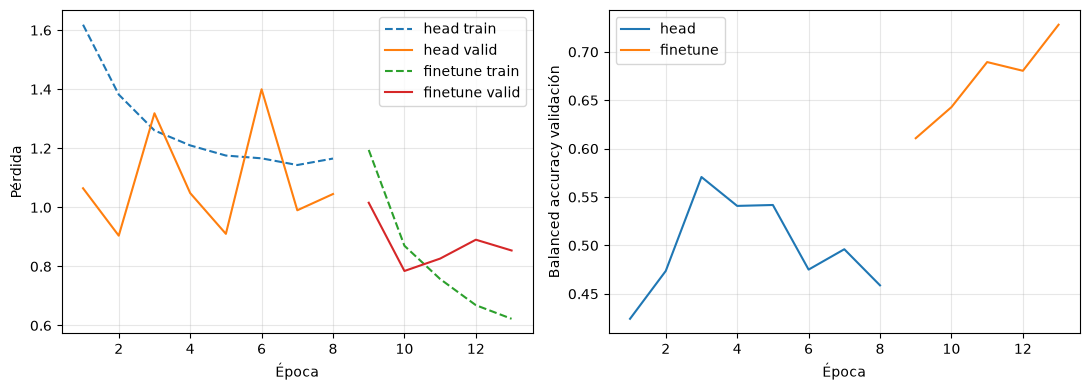

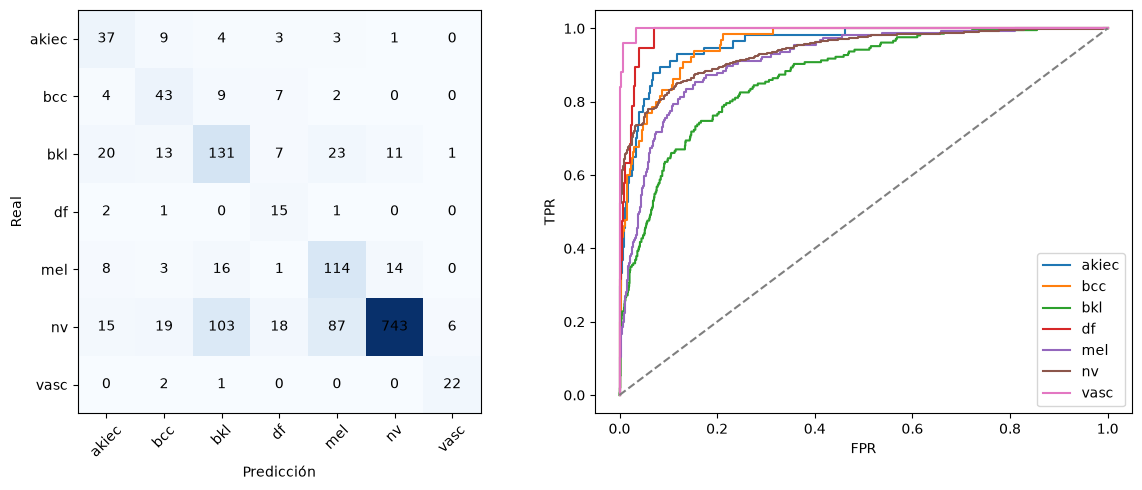

{'balanced_accuracy': 0.7280820347427064,
 'f1_macro': 0.6154494337149333,
 'classification_report': {'akiec': {'precision': 0.43023255813953487,
   'recall': 0.6491228070175439,
   'f1-score': 0.5174825174825175,
   'support': 57.0},
  'bcc': {'precision': 0.4777777777777778,
   'recall': 0.6615384615384615,
   'f1-score': 0.5548387096774193,
   'support': 65.0},
  'bkl': {'precision': 0.4962121212121212,
   'recall': 0.6359223300970874,
   'f1-score': 0.5574468085106383,
   'support': 206.0},
  'df': {'precision': 0.29411764705882354,
   'recall': 0.7894736842105263,
   'f1-score': 0.42857142857142855,
   'support': 19.0},
  'mel': {'precision': 0.4956521739130435,
   'recall': 0.7307692307692307,
   'f1-score': 0.5906735751295337,
   'support': 156.0},
  'nv': {'precision': 0.9661898569570871,
   'recall': 0.7497477295660948,
   'f1-score': 0.8443181818181819,
   'support': 991.0},
  'vasc': {'precision': 0.7586206896551724,
   'recall': 0.88,
   'f1-score': 0.8148148148148148,
   '

In [10]:
h2_plot=h2.copy(); h2_plot['epoch']+=len(h1)
plot_history({'head':h1,'finetune':h2_plot},RUNS/'multiclass')
display(report(model,frames['valid'],RUNS/'multiclass'/'validation_selected'))

## 8. Test final reservado

Activar después de fijar el protocolo. Los resultados existentes se conservan y no se cambia la selección tras consultar el test.

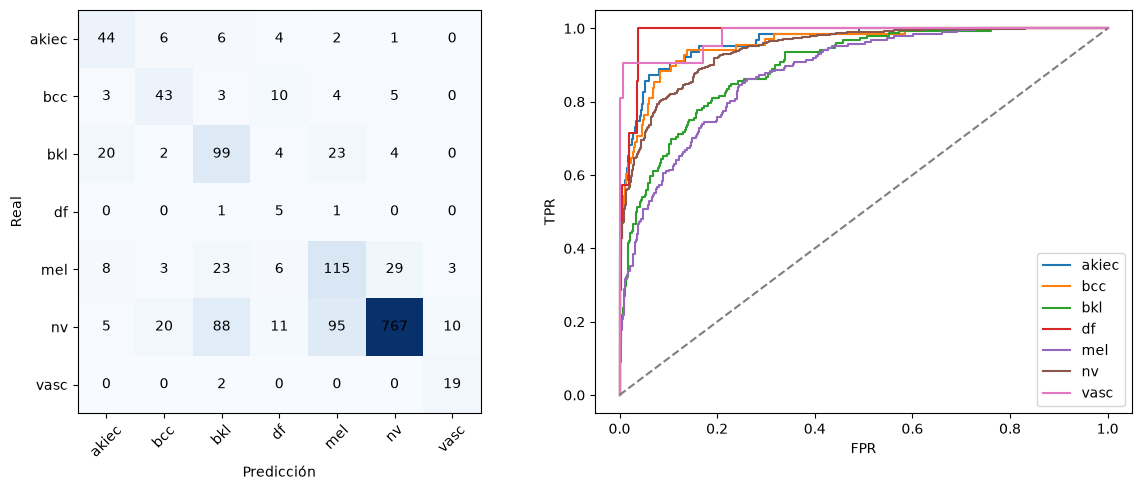

{'balanced_accuracy': 0.7123118044896712,
 'f1_macro': 0.5814421883161133,
 'classification_report': {'akiec': {'precision': 0.55,
   'recall': 0.6984126984126984,
   'f1-score': 0.6153846153846154,
   'support': 63.0},
  'bcc': {'precision': 0.581081081081081,
   'recall': 0.6323529411764706,
   'f1-score': 0.6056338028169014,
   'support': 68.0},
  'bkl': {'precision': 0.44594594594594594,
   'recall': 0.6513157894736842,
   'f1-score': 0.5294117647058824,
   'support': 152.0},
  'df': {'precision': 0.125,
   'recall': 0.7142857142857143,
   'f1-score': 0.2127659574468085,
   'support': 7.0},
  'mel': {'precision': 0.4791666666666667,
   'recall': 0.6149732620320856,
   'f1-score': 0.5386416861826698,
   'support': 187.0},
  'nv': {'precision': 0.9516129032258065,
   'recall': 0.7700803212851406,
   'f1-score': 0.8512763596004439,
   'support': 996.0},
  'vasc': {'precision': 0.59375,
   'recall': 0.9047619047619048,
   'f1-score': 0.7169811320754716,
   'support': 21.0},
  'accuracy

In [12]:
RUN_FINAL_TEST=True
if RUN_FINAL_TEST:
    assert MODE=='full', 'Test bloqueado para pruebas smoke.'
    lock=RUNS/'multiclass_test_lock.json'
    if lock.exists(): assert json.loads(lock.read_text())==selected, 'La selección cambió después de fijar el test.'
    else: lock.write_text(json.dumps(selected,indent=2))
    destination=RUNS/'final_test'/'multiclass'
    if (destination/'metrics.json').exists():
        print('Evaluación final ya guardada:',destination)
    else:
        model,head,last_block=make_transfer(selected['model'],7,pretrained=False)
        state=torch.load(Path(selected['folder'])/'best.pt',map_location=DEVICE,weights_only=False)
        assert state['signature']==selected['signature']; model.load_state_dict(state['model'])
        display(report(model,frames['test'],destination))
else:
    print('Test reservado: activar solo después de fijar configuración y selección por validación.')